In [1]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:

import os

MODEL_PATH = (
    "/content/drive/MyDrive/"
    "GAN_Medical_Project/models/generator_final.keras"
)

if os.path.exists(MODEL_PATH):
    print("SUCCESS: Generator model found!")
    print("File size:", round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2), "MB")
else:
    print("Model not found. Check the Google Drive folder path.")


SUCCESS: Generator model found!
File size: 8.92 MB


In [3]:

import tensorflow as tf
from tensorflow import keras
import os

generator = keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Generator loaded successfully!")
print("Input shape:", generator.input_shape)
print("Output shape:", generator.output_shape)


Generator loaded successfully!
Input shape: [(None, 128), (None, 9)]
Output shape: (None, 64, 64, 3)


In [4]:

!pip -q install kagglehub

import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "riyaelizashaju/skin-disease-classification-image-dataset"
)

print("Dataset downloaded to:", dataset_path)
print("\nTop-level contents:")

for item in os.listdir(dataset_path):
    full_path = os.path.join(dataset_path, item)
    kind = "Folder" if os.path.isdir(full_path) else "File"
    print(f"{kind}: {item}")


100%|██████████| 169M/169M [00:01<00:00, 107MB/s] 

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/riyaelizashaju/skin-disease-classification-image-dataset/versions/1

Top-level contents:
Folder: Split_smol


In [5]:

import os

split_path = os.path.join(dataset_path, "Split_smol")

print("Dataset structure:\n")

for root, dirs, files in os.walk(split_path):
    level = root.replace(split_path, "").count(os.sep)

    # Show only the first three directory levels
    if level <= 2:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        if level == 2:
            image_count = sum(
                1 for f in files
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
            )
            print(f"{indent}    Images: {image_count}")


Dataset structure:

Split_smol/
    train/
        Atopic Dermatitis/
            Images: 81
        Melanocytic nevus/
            Images: 80
        Benign keratosis/
            Images: 80
        Tinea Ringworm Candidiasis/
            Images: 56
        Dermatofibroma/
            Images: 80
        Actinic keratosis/
            Images: 80
        Vascular lesion/
            Images: 80
        Melanoma/
            Images: 80
        Squamous cell carcinoma/
            Images: 80
    val/
        Atopic Dermatitis/
            Images: 21
        Melanocytic nevus/
            Images: 20
        Benign keratosis/
            Images: 20
        Tinea Ringworm Candidiasis/
            Images: 20
        Dermatofibroma/
            Images: 20
        Actinic keratosis/
            Images: 20
        Vascular lesion/
            Images: 20
        Melanoma/
            Images: 20
        Squamous cell carcinoma/
            Images: 20


In [6]:

import os

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for split in ["train", "val", "test"]:
    split_dir = os.path.join(split_path, split)

    if not os.path.isdir(split_dir):
        print(f"\n{split}: folder not found")
        continue

    print(f"\n--- {split.upper()} ---")
    total = 0

    for class_name in sorted(os.listdir(split_dir)):
        class_dir = os.path.join(split_dir, class_name)

        if os.path.isdir(class_dir):
            count = sum(
                1 for name in os.listdir(class_dir)
                if name.lower().endswith(IMAGE_EXTENSIONS)
            )
            print(f"{class_name}: {count}")
            total += count

    print(f"TOTAL: {total}")



--- TRAIN ---
Actinic keratosis: 80
Atopic Dermatitis: 81
Benign keratosis: 80
Dermatofibroma: 80
Melanocytic nevus: 80
Melanoma: 80
Squamous cell carcinoma: 80
Tinea Ringworm Candidiasis: 56
Vascular lesion: 80
TOTAL: 697

--- VAL ---
Actinic keratosis: 20
Atopic Dermatitis: 21
Benign keratosis: 20
Dermatofibroma: 20
Melanocytic nevus: 20
Melanoma: 20
Squamous cell carcinoma: 20
Tinea Ringworm Candidiasis: 20
Vascular lesion: 20
TOTAL: 181

test: folder not found


In [7]:

import os

train_dir = os.path.join(split_path, "train")

# The original notebook uses image_dataset_from_directory,
# which orders class names alphabetically.
class_names = sorted([
    name for name in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, name))
])

print("Number of classes:", len(class_names))
print("\nClass index mapping:")

for index, name in enumerate(class_names):
    print(f"{index}: {name}")

print("\nGenerator output shape:", generator.output_shape)


Number of classes: 9

Class index mapping:
0: Actinic keratosis
1: Atopic Dermatitis
2: Benign keratosis
3: Dermatofibroma
4: Melanocytic nevus
5: Melanoma
6: Squamous cell carcinoma
7: Tinea Ringworm Candidiasis
8: Vascular lesion

Generator output shape: (None, 64, 64, 3)


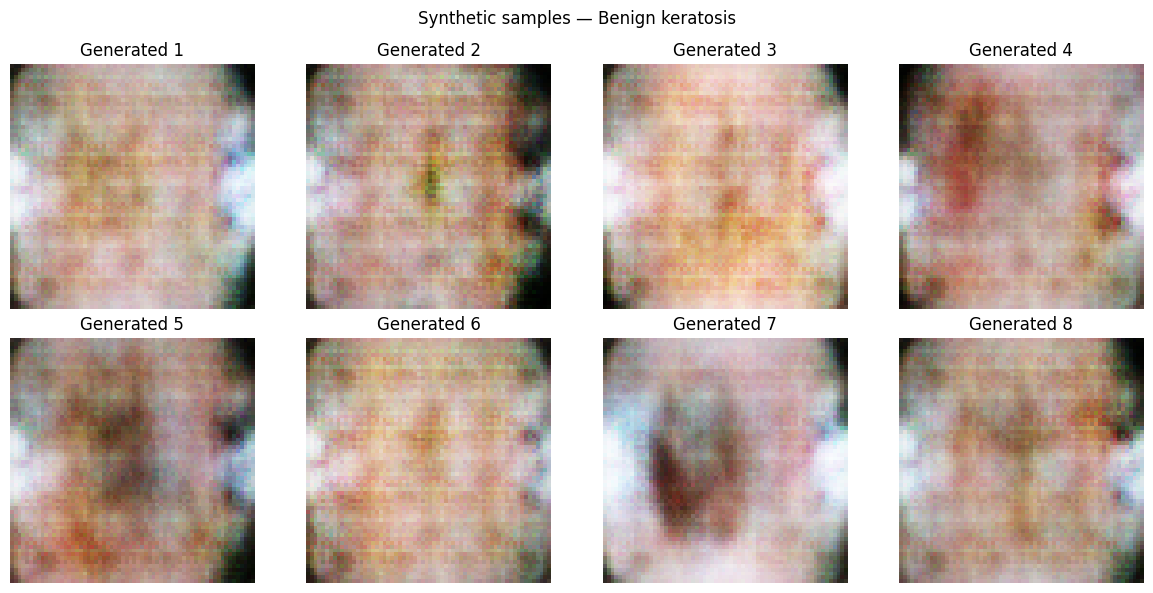

In [8]:

import numpy as np
import matplotlib.pyplot as plt

# Select a class for the initial visual check
class_index = 2  # Benign keratosis
num_images = 8

# Random noise vectors
noise = tf.random.normal((num_images, 128))

# One-hot class labels
labels = tf.one_hot(
    [class_index] * num_images,
    depth=9
)

# Generate images
generated = generator([noise, labels], training=False).numpy()

# Convert pixel range from [-1, 1] to [0, 1]
generated = np.clip((generated + 1.0) / 2.0, 0, 1)

# Display the generated images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated[i])
    ax.axis("off")
    ax.set_title(f"Generated {i + 1}")

plt.suptitle(f"Synthetic samples — {class_names[class_index]}")
plt.tight_layout()
plt.show()


In [9]:

from PIL import Image
import os
import numpy as np

OUTPUT_DIR = (
    "/content/drive/MyDrive/"
    "GAN_Medical_Project/generated_samples"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

class_folder = os.path.join(
    OUTPUT_DIR, class_names[class_index].replace(" ", "_")
)
os.makedirs(class_folder, exist_ok=True)

for i, img in enumerate(generated):
    img_uint8 = (img * 255).astype(np.uint8)
    Image.fromarray(img_uint8).save(
        os.path.join(class_folder, f"sample_{i+1:02d}.png")
    )

print("Saved", len(generated), "images to:")
print(class_folder)


Saved 8 images to:
/content/drive/MyDrive/GAN_Medical_Project/generated_samples/Benign_keratosis


In [10]:

import tensorflow as tf
from tensorflow import keras

IMG_SIZE = 64
BATCH_SIZE = 32
SEED = 42

train_dir = os.path.join(split_path, "train")
val_dir = os.path.join(split_path, "val")

train_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

print("\nTraining classes:", train_ds.class_names)
print("Validation classes:", val_ds.class_names)


Found 697 files belonging to 9 classes.
Found 181 files belonging to 9 classes.

Training classes: ['Actinic keratosis', 'Atopic Dermatitis', 'Benign keratosis', 'Dermatofibroma', 'Melanocytic nevus', 'Melanoma', 'Squamous cell carcinoma', 'Tinea Ringworm Candidiasis', 'Vascular lesion']
Validation classes: ['Actinic keratosis', 'Atopic Dermatitis', 'Benign keratosis', 'Dermatofibroma', 'Melanocytic nevus', 'Melanoma', 'Squamous cell carcinoma', 'Tinea Ringworm Candidiasis', 'Vascular lesion']


In [11]:

from tensorflow import keras
from tensorflow.keras import layers

NUM_CLASSES = len(train_ds.class_names)

def build_classifier():
    model = keras.Sequential([
        keras.Input(shape=(64, 64, 3)),

        # Normalize pixels from [0, 255] to [0, 1]
        layers.Rescaling(1.0 / 255),

        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

baseline_model = build_classifier()
baseline_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,089 (398.79 KB)

 Trainable params: 102,089 (398.79 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:

EPOCHS_CNN = 10

history_real = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CNN
)


Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 14s 542ms/step - accuracy: 0.1406 - loss: 2.1929 - val_accuracy: 0.1215 - val_loss: 2.1853
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 12s 548ms/step - accuracy: 0.1521 - loss: 2.1552 - val_accuracy: 0.1768 - val_loss: 2.1061
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 460ms/step - accuracy: 0.2209 - loss: 2.0739 - val_accuracy: 0.1768 - val_loss: 2.0800
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 12s 539ms/step - accuracy: 0.2410 - loss: 1.9969 - val_accuracy: 0.2873 - val_loss: 1.9334
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 12s 538ms/step - accuracy: 0.2539 - loss: 1.8928 - val_accuracy: 0.2928 - val_loss: 1.7914
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 12s 521ms/step - accuracy: 0.2898 - loss: 1.8224 - val_accuracy: 0.3260 - val_loss: 1.7092
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 20s 507ms/step - accuracy: 0.3228 - loss: 1.7572 - val_accuracy: 0.2210 - val_loss: 1.7444
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 11s 512ms/step - accuracy: 0.3027 - loss: 1.7915 - val_accu

Validation accuracy: 0.2928

Classification report:
                            precision    recall  f1-score   support

         Actinic keratosis       0.08      0.05      0.06        20
         Atopic Dermatitis       0.35      0.76      0.48        21
          Benign keratosis       0.33      0.15      0.21        20
            Dermatofibroma       0.00      0.00      0.00        20
         Melanocytic nevus       0.36      0.80      0.49        20
                  Melanoma       0.33      0.20      0.25        20
   Squamous cell carcinoma       0.18      0.15      0.16        20
Tinea Ringworm Candidiasis       0.00      0.00      0.00        20
           Vascular lesion       0.27      0.50      0.35        20

                  accuracy                           0.29       181
                 macro avg       0.21      0.29      0.22       181
              weighted avg       0.21      0.29      0.22       181



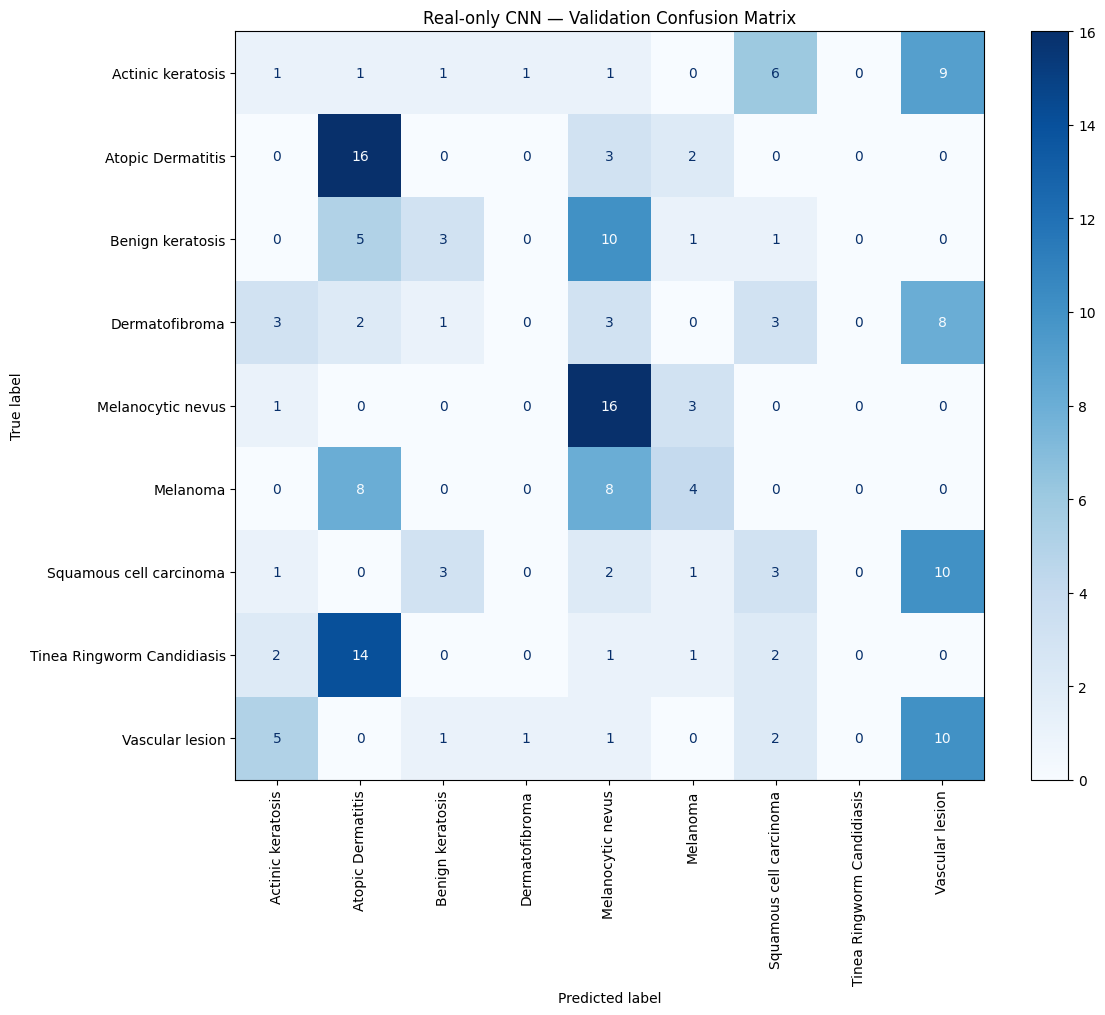

In [13]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)

# Collect the true labels from the validation set
y_true = np.concatenate([
    labels.numpy()
    for images, labels in val_ds
])

# Predict the classes
y_prob = baseline_model.predict(val_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Calculate metrics
print("Validation accuracy:",
      round(accuracy_score(y_true, y_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

# Plot the confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

fig, ax = plt.subplots(figsize=(12, 10))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=90, values_format="d")
plt.title("Real-only CNN — Validation Confusion Matrix")
plt.tight_layout()
plt.show()


In [14]:

import os
import numpy as np
import tensorflow as tf
from PIL import Image

SYNTH_DIR = (
    "/content/drive/MyDrive/"
    "GAN_Medical_Project/synthetic_dataset"
)

os.makedirs(SYNTH_DIR, exist_ok=True)

SAMPLES_PER_CLASS = 20
LATENT_DIM = 128

for class_index, class_name in enumerate(class_names):
    class_folder = os.path.join(
        SYNTH_DIR, class_name.replace(" ", "_")
    )
    os.makedirs(class_folder, exist_ok=True)

    noise = tf.random.normal(
        (SAMPLES_PER_CLASS, LATENT_DIM)
    )
    labels = tf.one_hot(
        [class_index] * SAMPLES_PER_CLASS,
        depth=NUM_CLASSES
    )

    images = generator([noise, labels], training=False).numpy()
    images = np.clip((images + 1.0) / 2.0, 0, 1)

    for i, image in enumerate(images):
        image_uint8 = (image * 255).astype(np.uint8)
        Image.fromarray(image_uint8).save(
            os.path.join(class_folder, f"synthetic_{i+1:02d}.png")
        )

    print(f"{class_name}: saved {len(images)} images")

print("\nSynthetic dataset saved to:", SYNTH_DIR)


Actinic keratosis: saved 20 images
Atopic Dermatitis: saved 20 images
Benign keratosis: saved 20 images
Dermatofibroma: saved 20 images
Melanocytic nevus: saved 20 images
Melanoma: saved 20 images
Squamous cell carcinoma: saved 20 images
Tinea Ringworm Candidiasis: saved 20 images
Vascular lesion: saved 20 images

Synthetic dataset saved to: /content/drive/MyDrive/GAN_Medical_Project/synthetic_dataset


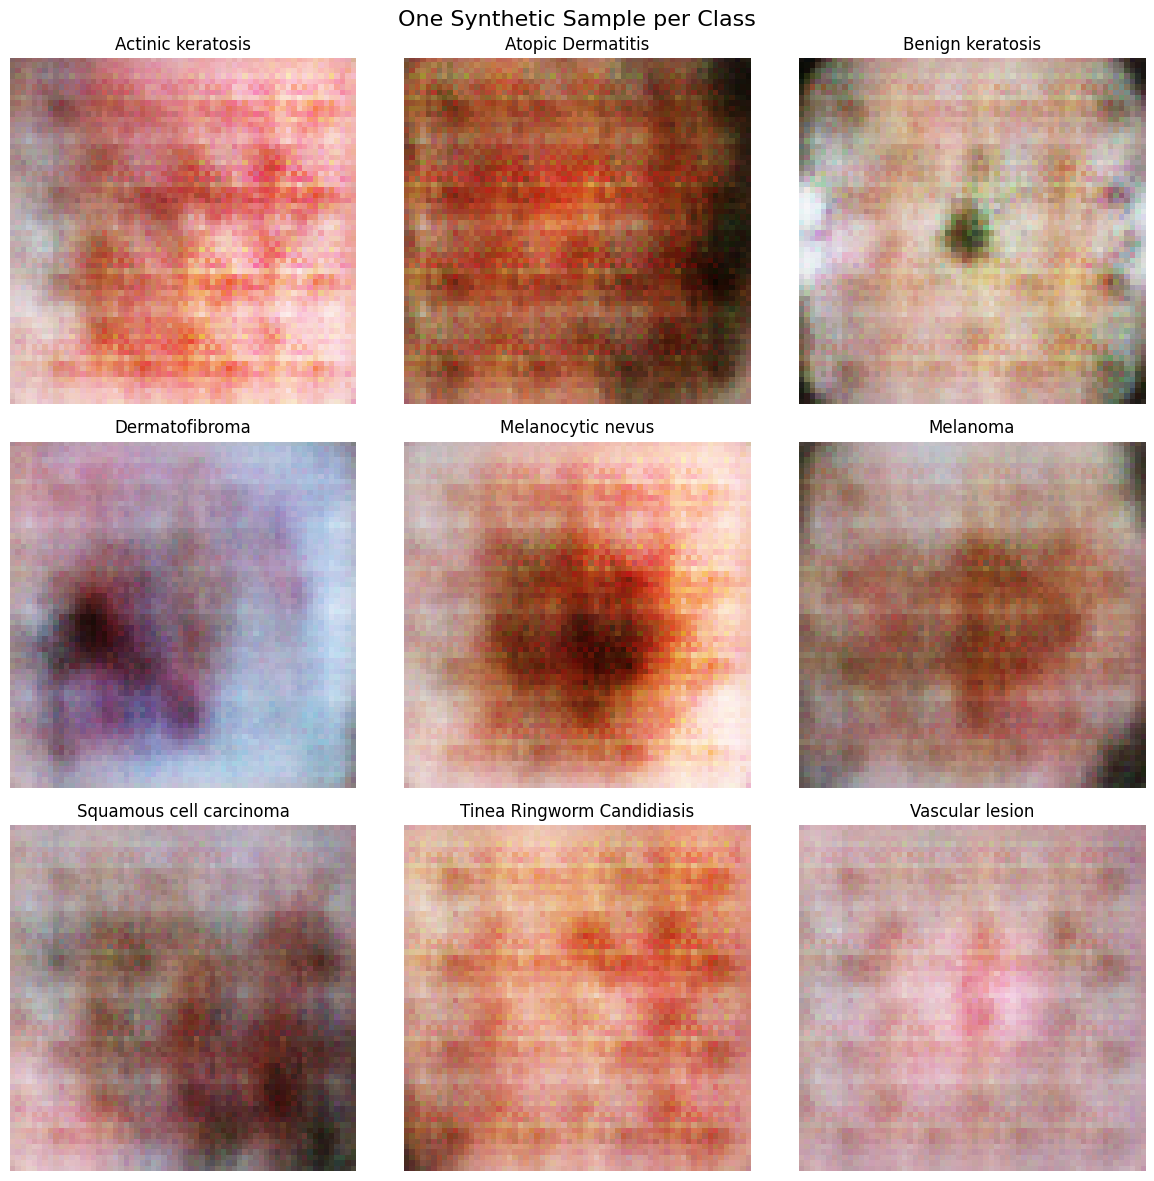

In [15]:

import os
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for i, class_name in enumerate(class_names):
    class_folder = os.path.join(
        SYNTH_DIR, class_name.replace(" ", "_")
    )

    image_files = sorted([
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    image_path = os.path.join(class_folder, image_files[0])
    image = Image.open(image_path).convert("RGB")

    ax = axes.flat[i]
    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("One Synthetic Sample per Class", fontsize=16)
plt.tight_layout()
plt.show()


In [16]:

import os
import numpy as np
import tensorflow as tf
from PIL import Image
from sklearn.metrics import classification_report, accuracy_score

synthetic_images = []
synthetic_labels = []

for class_index, class_name in enumerate(class_names):
    class_folder = os.path.join(
        SYNTH_DIR, class_name.replace(" ", "_")
    )

    image_files = sorted([
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    for filename in image_files:
        image_path = os.path.join(class_folder, filename)

        image = Image.open(image_path).convert("RGB")
        image = image.resize((64, 64))

        synthetic_images.append(np.asarray(image))
        synthetic_labels.append(class_index)

X_synthetic = np.asarray(synthetic_images, dtype=np.float32)
y_synthetic = np.asarray(synthetic_labels, dtype=np.int32)

print("Synthetic images:", len(X_synthetic))
print("Image array shape:", X_synthetic.shape)

# The classifier internally rescales pixels from [0, 255] to [0, 1].
probabilities = baseline_model.predict(X_synthetic, verbose=0)
predictions = np.argmax(probabilities, axis=1)

print(
    "\nClassifier agreement with requested labels:",
    round(accuracy_score(y_synthetic, predictions), 4)
)

print("\nPer-class results:")
print(classification_report(
    y_synthetic,
    predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))


Synthetic images: 180
Image array shape: (180, 64, 64, 3)

Classifier agreement with requested labels: 0.2111

Per-class results:
                            precision    recall  f1-score   support

         Actinic keratosis       0.00      0.00      0.00        20
         Atopic Dermatitis       0.20      0.95      0.33        20
          Benign keratosis       0.00      0.00      0.00        20
            Dermatofibroma       0.00      0.00      0.00        20
         Melanocytic nevus       0.19      0.45      0.27        20
                  Melanoma       0.12      0.15      0.14        20
   Squamous cell carcinoma       0.00      0.00      0.00        20
Tinea Ringworm Candidiasis       0.00      0.00      0.00        20
           Vascular lesion       1.00      0.35      0.52        20

                  accuracy                           0.21       180
                 macro avg       0.17      0.21      0.14       180
              weighted avg       0.17      0.21     

In [17]:

# Build a dataset from the 180 synthetic images
synthetic_ds = tf.data.Dataset.from_tensor_slices(
    (X_synthetic, y_synthetic)
)

# Combine real training images with synthetic images
combined_ds = (
    train_ds.unbatch()
    .concatenate(synthetic_ds)
    .shuffle(1000, seed=42, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Real training images:", 697)
print("Synthetic images:", len(X_synthetic))
print("Combined training images:", 697 + len(X_synthetic))

# Train a fresh CNN with the same architecture
augmented_model = build_classifier()

history_augmented = augmented_model.fit(
    combined_ds,
    validation_data=val_ds,
    epochs=10
)


Real training images: 697
Synthetic images: 180
Combined training images: 877
Epoch 1/10
     28/Unknown 16s 234ms/step - accuracy: 0.1404 - loss: 2.2005

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 277ms/step - accuracy: 0.1368 - loss: 2.1942 - val_accuracy: 0.2044 - val_loss: 2.1624
Epoch 2/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 19s 348ms/step - accuracy: 0.2018 - loss: 2.1001 - val_accuracy: 0.1713 - val_loss: 2.0583
Epoch 3/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 21s 373ms/step - accuracy: 0.2235 - loss: 2.0283 - val_accuracy: 0.2320 - val_loss: 1.9849
Epoch 4/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 368ms/step - accuracy: 0.2828 - loss: 1.9127 - val_accuracy: 0.3204 - val_loss: 1.7985
Epoch 5/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 373ms/step - accuracy: 0.2805 - loss: 1.8572 - val_accuracy: 0.2431 - val_loss: 1.8255
Epoch 6/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 20s 356ms/step - accuracy: 0.2919 - loss: 1.8478 - val_accuracy: 0.2652 - val_loss: 1.7987
Epoch 7/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 356ms/step - accuracy: 0.3193 - loss: 1.7224 - val_accuracy: 0.3370 - val_loss: 1.6949
Epoch 8/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 21s 310ms/step - accuracy: 0.3090 - loss: 1.7104 - val_accuracy: 0.326

In [18]:

# Rebuild the combined dataset and repeat it so every epoch
# has enough batches.
combined_ds_fixed = (
    train_ds.unbatch()
    .concatenate(synthetic_ds)
    .shuffle(1000, seed=42, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .repeat()
    .prefetch(tf.data.AUTOTUNE)
)

TOTAL_TRAIN_IMAGES = 697 + len(X_synthetic)
STEPS_PER_EPOCH = int(np.ceil(TOTAL_TRAIN_IMAGES / BATCH_SIZE))

print("Images per epoch:", TOTAL_TRAIN_IMAGES)
print("Steps per epoch:", STEPS_PER_EPOCH)

# Fresh model for a clean rerun
augmented_model_fixed = build_classifier()

history_augmented_fixed = augmented_model_fixed.fit(
    combined_ds_fixed,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=val_ds,
    epochs=10
)


Images per epoch: 877
Steps per epoch: 28
Epoch 1/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 18s 409ms/step - accuracy: 0.1334 - loss: 2.1808 - val_accuracy: 0.1823 - val_loss: 2.1415
Epoch 2/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 12s 396ms/step - accuracy: 0.2064 - loss: 2.0798 - val_accuracy: 0.2707 - val_loss: 2.0391
Epoch 3/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 417ms/step - accuracy: 0.2223 - loss: 1.9723 - val_accuracy: 0.2873 - val_loss: 1.8933
Epoch 4/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 12s 376ms/step - accuracy: 0.2554 - loss: 1.9096 - val_accuracy: 0.2762 - val_loss: 1.7487
Epoch 5/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 461ms/step - accuracy: 0.2645 - loss: 1.8473 - val_accuracy: 0.2652 - val_loss: 1.7292
Epoch 6/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 466ms/step - accuracy: 0.2862 - loss: 1.8285 - val_accuracy: 0.2983 - val_loss: 1.7174
Epoch 7/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 13s 465ms/step - accuracy: 0.3204 - loss: 1.7637 - val_accuracy: 0.3149 - val_loss: 1.7214
Epoch 8/10
28/28 ━━━━━━━━━━━━━━━━━━━━ 12s 444ms/step - 

In [19]:

import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# Identify the best validation-accuracy epoch for each run
best_real_epoch = int(np.argmax(history_real.history["val_accuracy"]))
best_aug_epoch = int(np.argmax(
    history_augmented_fixed.history["val_accuracy"]
))

print("Best real-only epoch:", best_real_epoch + 1)
print("Best real-only validation accuracy:",
      round(history_real.history["val_accuracy"][best_real_epoch], 4))

print("\nBest augmented epoch:", best_aug_epoch + 1)
print("Best augmented validation accuracy:",
      round(history_augmented_fixed.history["val_accuracy"][best_aug_epoch], 4))

# Evaluate the currently held models as a consistent metric check
y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

real_pred = np.argmax(
    baseline_model.predict(val_ds, verbose=0), axis=1
)
aug_pred = np.argmax(
    augmented_model_fixed.predict(val_ds, verbose=0), axis=1
)

print("\nCurrent real-only accuracy:",
      round(accuracy_score(y_true, real_pred), 4))
print("Current real-only macro F1:",
      round(f1_score(y_true, real_pred, average="macro",
                     zero_division=0), 4))

print("\nCurrent augmented accuracy:",
      round(accuracy_score(y_true, aug_pred), 4))
print("Current augmented macro F1:",
      round(f1_score(y_true, aug_pred, average="macro",
                     zero_division=0), 4))


Best real-only epoch: 6
Best real-only validation accuracy: 0.326

Best augmented epoch: 7
Best augmented validation accuracy: 0.3149

Current real-only accuracy: 0.2928
Current real-only macro F1: 0.2223

Current augmented accuracy: 0.2873
Current augmented macro F1: 0.2315


In [20]:

import os
import json

RESULTS_DIR = (
    "/content/drive/MyDrive/"
    "GAN_Medical_Project/results"
)
os.makedirs(RESULTS_DIR, exist_ok=True)

baseline_model.save(
    os.path.join(RESULTS_DIR, "real_only_final.keras")
)

augmented_model_fixed.save(
    os.path.join(RESULTS_DIR, "real_plus_synthetic_final.keras")
)

histories = {
    "real_only": history_real.history,
    "real_plus_synthetic": history_augmented_fixed.history
}

with open(
    os.path.join(RESULTS_DIR, "training_histories.json"),
    "w"
) as f:
    json.dump(histories, f, indent=2)

print("Models and training histories saved to:")
print(RESULTS_DIR)


Models and training histories saved to:
/content/drive/MyDrive/GAN_Medical_Project/results


,Experiment,Best validation accuracy (%),Final validation accuracy (%),Training images
0,Real-only CNN,32.60,29.28,697
1,Real + synthetic CNN,31.49,28.73,877


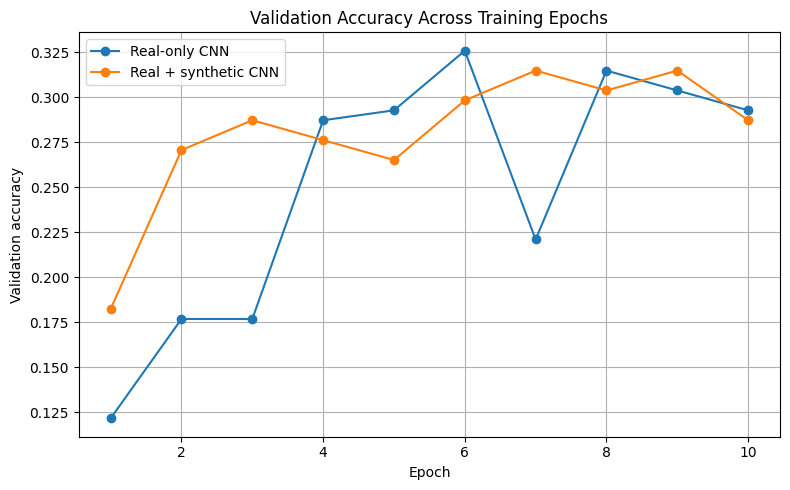

Results table and plot saved to: /content/drive/MyDrive/GAN_Medical_Project/results


In [21]:

import pandas as pd
import matplotlib.pyplot as plt

results_table = pd.DataFrame([
    {
        "Experiment": "Real-only CNN",
        "Best validation accuracy (%)": round(
            max(history_real.history["val_accuracy"]) * 100, 2
        ),
        "Final validation accuracy (%)": round(
            history_real.history["val_accuracy"][-1] * 100, 2
        ),
        "Training images": 697
    },
    {
        "Experiment": "Real + synthetic CNN",
        "Best validation accuracy (%)": round(
            max(history_augmented_fixed.history["val_accuracy"]) * 100, 2
        ),
        "Final validation accuracy (%)": round(
            history_augmented_fixed.history["val_accuracy"][-1] * 100, 2
        ),
        "Training images": 877
    }
])

display(results_table)

results_table.to_csv(
    os.path.join(RESULTS_DIR, "results_summary.csv"),
    index=False
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(history_real.history["val_accuracy"]) + 1),
    history_real.history["val_accuracy"],
    marker="o",
    label="Real-only CNN"
)

plt.plot(
    range(1, len(history_augmented_fixed.history["val_accuracy"]) + 1),
    history_augmented_fixed.history["val_accuracy"],
    marker="o",
    label="Real + synthetic CNN"
)

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Validation Accuracy Across Training Epochs")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "validation_accuracy.png"),
    dpi=200
)
plt.show()

print("Results table and plot saved to:", RESULTS_DIR)
